# Module 5 — Data Visualization

**Modular Daraz Analysis — Module 5 of 6**

**Purpose.** Turn the descriptive and relationship analysis into interpretable charts using Matplotlib, with one clear question per visualization.

**Course concepts visible in this part:** Matplotlib figures, bar/barh charts, pie chart, histogram, scatter plots, subplots, pivot tables, labels, grids and visual interpretation.

**Project rule:** This notebook is one stage of the same Daraz analysis. It does not use separate practice examples; every concept is applied to the real project data.

## Load the analysis-ready output from Module 3
The visualization stage uses the already cleaned and classified dataset. Every chart is tied to a project question and followed by interpretation.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

df = pd.read_csv("daraz_analysis_ready.csv")
print("Visualization data shape:", df.shape)

Visualization data shape: (1051, 12)


**1. how many product records are in each category**

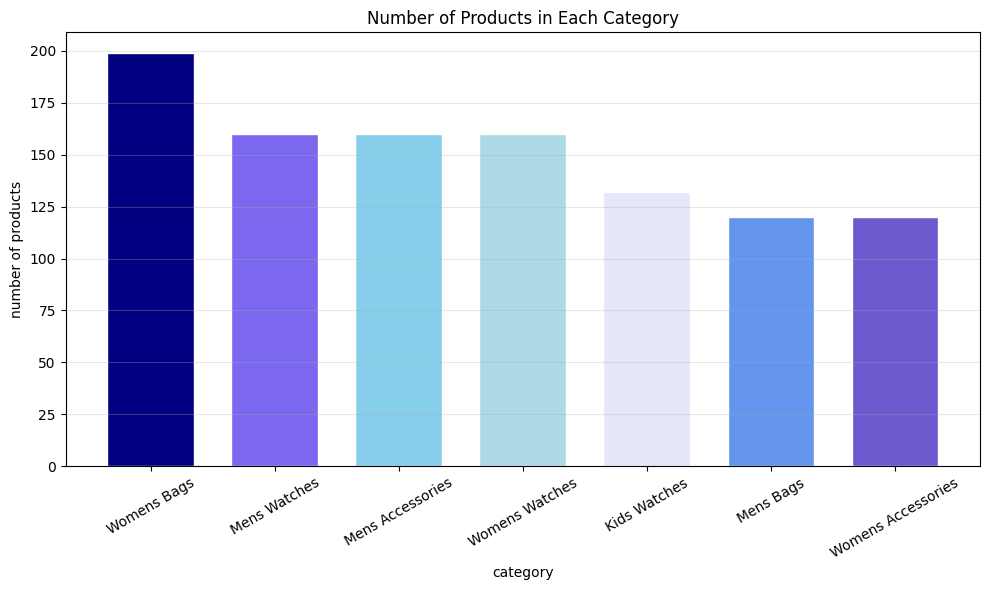

In [2]:
counts = df["Category"].value_counts()

plt.figure(figsize=(10, 6))
plt.bar(counts.index, counts.values,
        color=["navy", "mediumslateblue", "skyblue", "lightblue", "lavender", "cornflowerblue", "slateblue"],
        edgecolor="white",
        width=0.7)
plt.title("Number of Products in Each Category")
plt.xlabel("category")
plt.ylabel("number of products")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Womens Bags has the most product records at 199. Kids Watches falls to 132 after repeated product links are removed. A bar chart is appropriate because the question is a comparison of category counts.

**2. which category is most expensive**

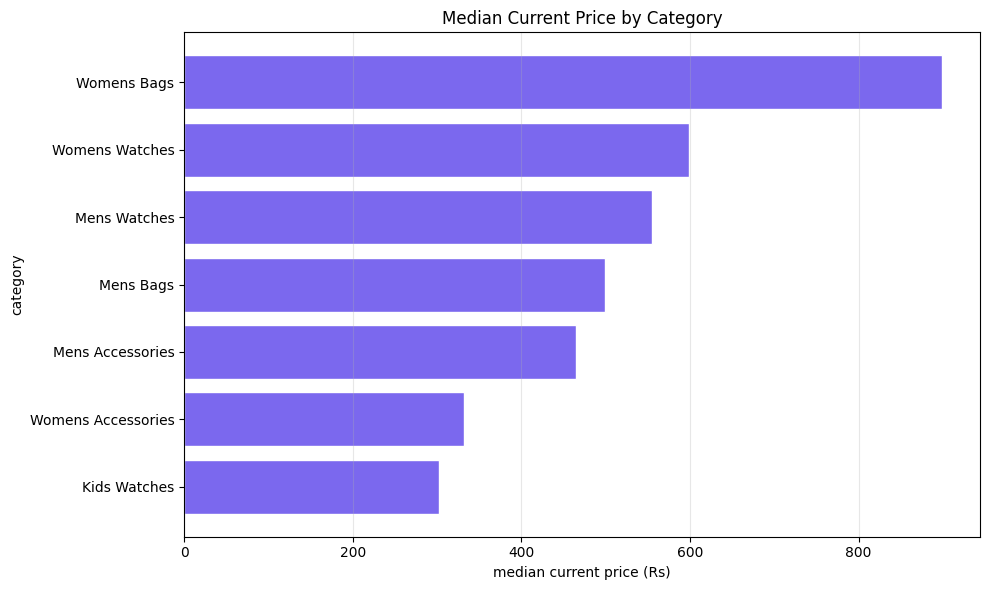

In [3]:
prices = df.groupby("Category")["Current Price"].median().sort_values()

plt.figure(figsize=(10, 6))
plt.barh(prices.index, prices.values,
         color="mediumslateblue",
         edgecolor="white")
plt.title("Median Current Price by Category")
plt.xlabel("median current price (Rs)")
plt.ylabel("category")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

Womens Bags has the highest median current price at **Rs 899**, while Kids Watches has the lowest at about **Rs 302.5**. We use the median rather than the mean because the price distribution is strongly right-skewed.

**3. the three price groups**

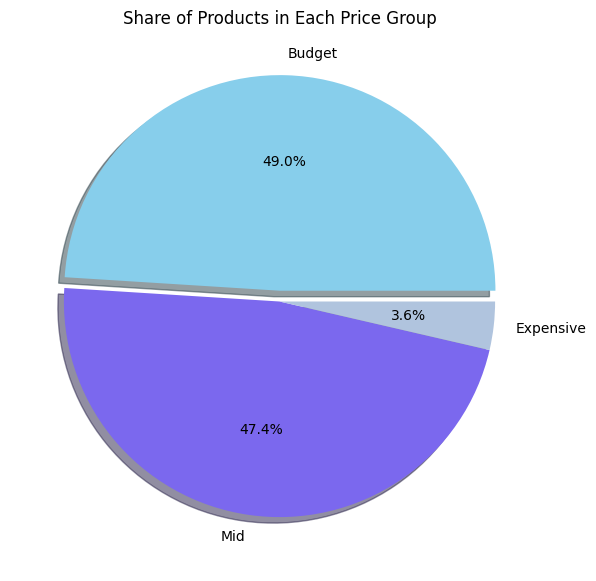

In [4]:
groups = df["Price Group"].value_counts()

plt.figure(figsize=(7, 7))
plt.pie(groups.values,
        labels=groups.index,
        colors=["skyblue", "mediumslateblue", "lightsteelblue"],
        autopct="%1.1f%%",
        explode=[0.05, 0, 0],
        shadow=True,
        textprops={"color": "black"})
plt.title("Share of Products in Each Price Group")
plt.show()

About half of the cleaned product records are below Rs 500, while only a small share is Rs 2000 or more. The pie chart is used only because these three price groups are mutually exclusive parts of the same dataset.

**4. what the prices look like overall**

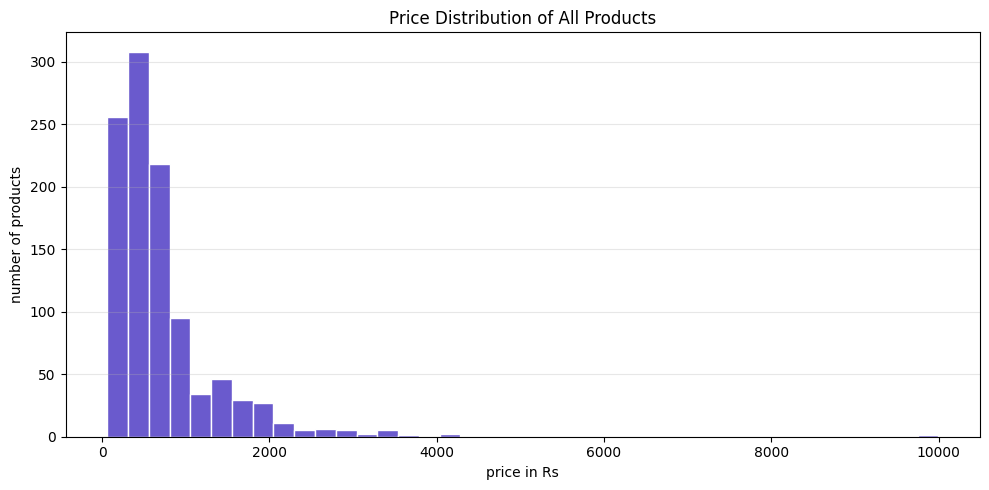

In [5]:
plt.figure(figsize=(10, 5))
plt.hist(df["Current Price"], bins=40,
         color="slateblue",
         edgecolor="white")
plt.title("Price Distribution of All Products")
plt.xlabel("price in Rs")
plt.ylabel("number of products")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Most prices are concentrated toward the lower end, with a long right tail created by a small number of expensive products. This visual explains why the mean price is higher than the median and supports our decision to use medians for category comparisons.

**5. what actually sells**

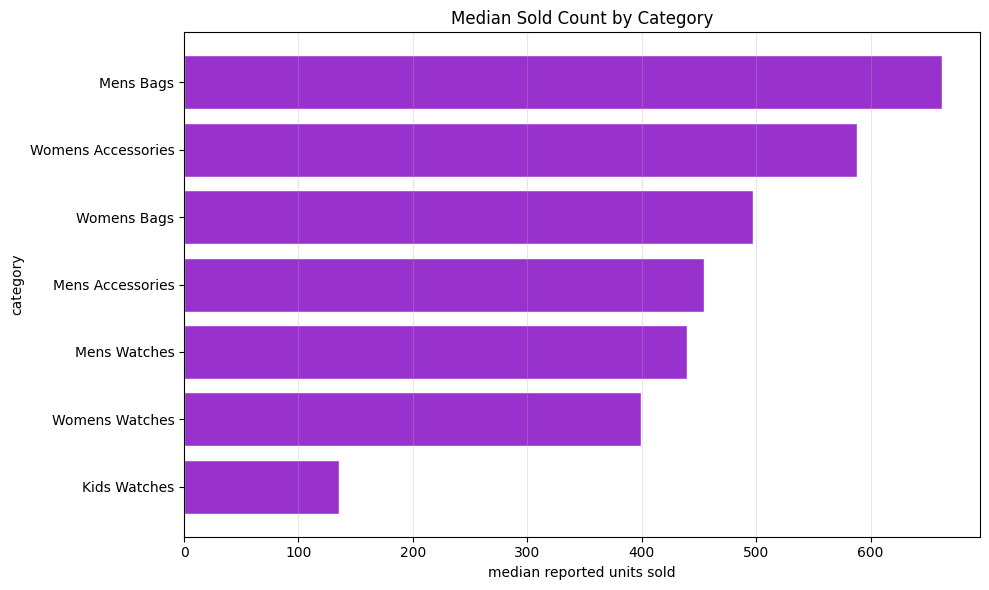

In [6]:
sold = df.groupby("Category")["Sold Count"].median().sort_values()

plt.figure(figsize=(10, 6))
plt.barh(sold.index, sold.values,
         color="darkorchid",
         edgecolor="white")
plt.title("Median Sold Count by Category")
plt.xlabel("median reported units sold")
plt.ylabel("category")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

Mens Bags has the highest median reported sold count at **662.5**, while Kids Watches has the lowest at **135**. Kids Watches is also the cheapest category, so the category comparison does not support the idea that lower price automatically means higher sales.

**6. average star rating by category**

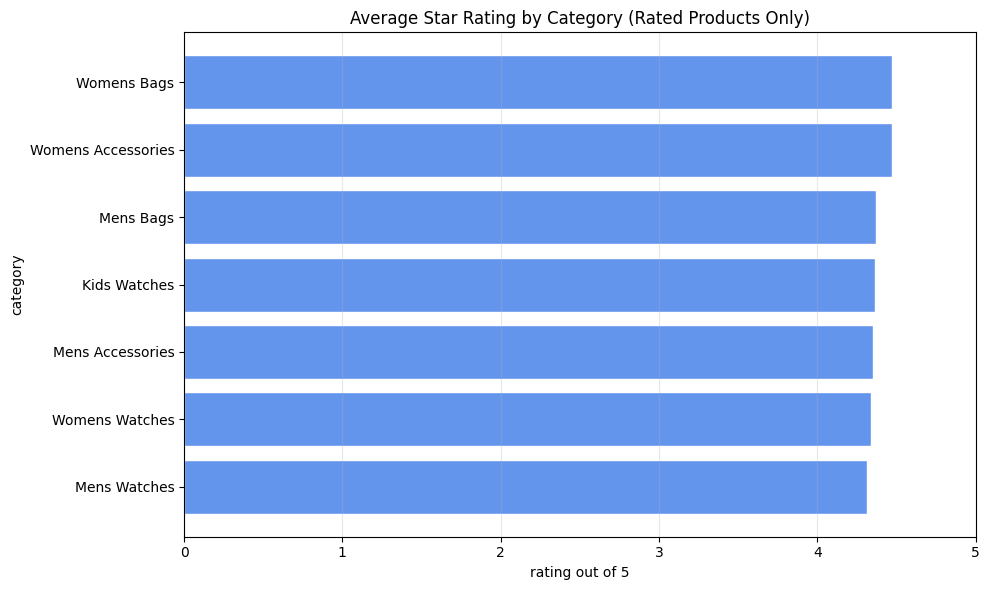

In [7]:
ratings = df.groupby("Category")["Rating in Stars"].mean().sort_values()

plt.figure(figsize=(10, 6))
plt.barh(ratings.index, ratings.values,
         color="cornflowerblue",
         edgecolor="white")
plt.title("Average Star Rating by Category (Rated Products Only)")
plt.xlabel("rating out of 5")
plt.ylabel("category")
plt.xlim(0, 5)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

After treating unrated products as missing rather than as 0-star reviews, every category still has a high average rating, roughly between **4.32 and 4.47**. The differences are small. Keeping the x-axis at the full 0-to-5 scale avoids exaggerating a difference of only a few tenths of a star.

**7. does price affect how much sells**

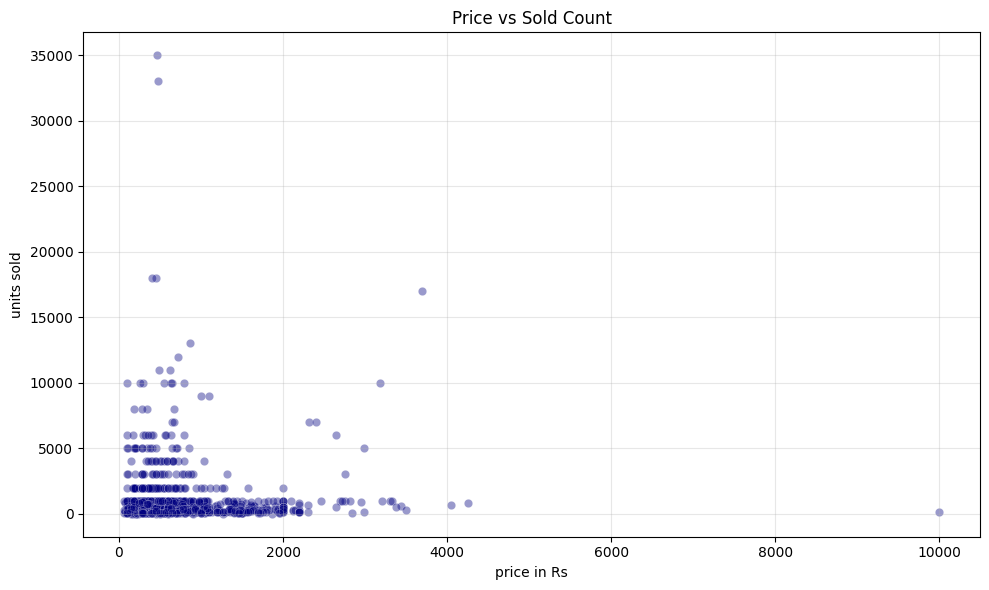

correlation: -0.001


In [8]:
plt.figure(figsize=(10, 6))
plt.scatter(df["Current Price"], df["Sold Count"],
            color="navy",
            alpha=0.4,
            edgecolor="white",
            linewidth=0.3)
plt.title("Price vs Sold Count")
plt.xlabel("price in Rs")
plt.ylabel("units sold")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("correlation:", round(df["Current Price"].corr(df["Sold Count"]), 3))

The scatter plot shows no meaningful linear relationship between current price and reported sold count. The correlation is essentially zero. In this dataset, knowing a product's current price does not help us predict how much it has sold. This is an association result, not a claim that price can never affect demand in other markets or datasets.

**8. rating count and sold count — the strongest relationship**

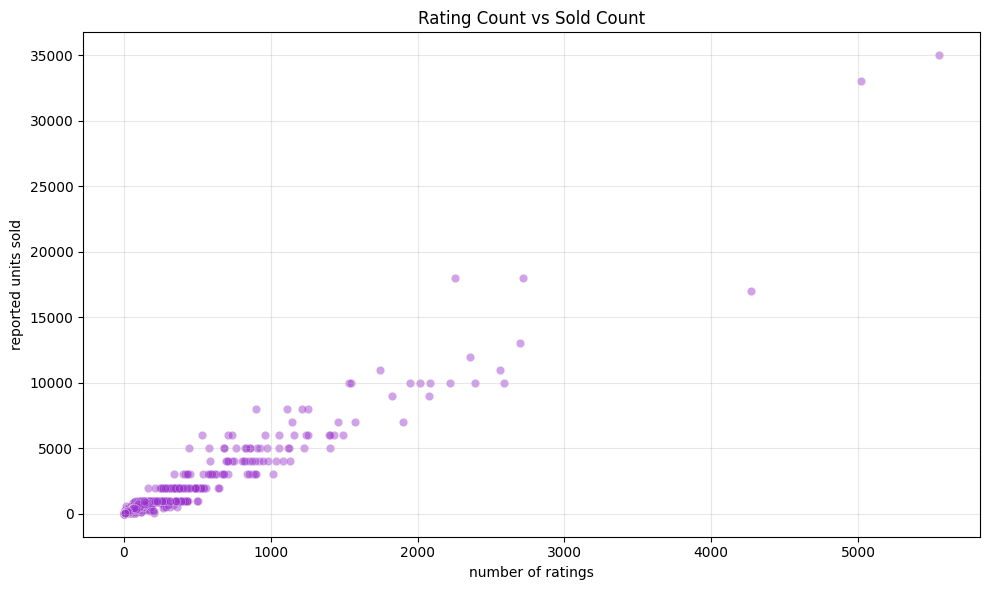

correlation: 0.964


In [9]:
plot_data = df.dropna(subset=["Rating Count", "Sold Count"])

plt.figure(figsize=(10, 6))
plt.scatter(plot_data["Rating Count"], plot_data["Sold Count"],
            color="darkorchid", alpha=0.45,
            edgecolor="white", linewidth=0.3)
plt.title("Rating Count vs Sold Count")
plt.xlabel("number of ratings")
plt.ylabel("reported units sold")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("correlation:", round(plot_data["Rating Count"].corr(plot_data["Sold Count"]), 3))

This is the clearest numerical relationship in the project. Products with more ratings also tend to have much higher reported sold counts. The correlation is very strong, but we should not say ratings **cause** sales: purchases create opportunities for customers to leave ratings, so both variables are also measuring product popularity.

**9. does a larger discount percentage correspond to higher sales?**

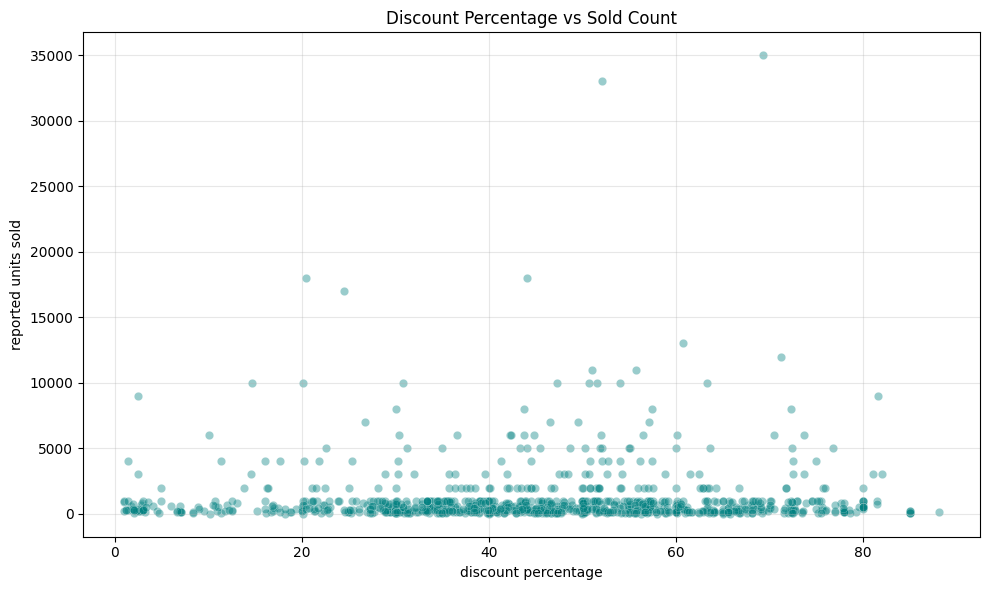

correlation: 0.028


In [10]:
discount_plot = df.dropna(subset=["Discount %", "Sold Count"])

plt.figure(figsize=(10, 6))
plt.scatter(discount_plot["Discount %"], discount_plot["Sold Count"],
            color="teal", alpha=0.4,
            edgecolor="white", linewidth=0.3)
plt.title("Discount Percentage vs Sold Count")
plt.xlabel("discount percentage")
plt.ylabel("reported units sold")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("correlation:", round(discount_plot["Discount %"].corr(discount_plot["Sold Count"]), 3))

The points are widely scattered and the correlation is close to zero. In this dataset, a larger displayed discount percentage is **not strongly associated** with a higher reported sold count. This does not prove discounts are ineffective; we do not know product age, campaign timing, visibility or how long each discount was active.

**10. overall free-delivery and voucher comparison**

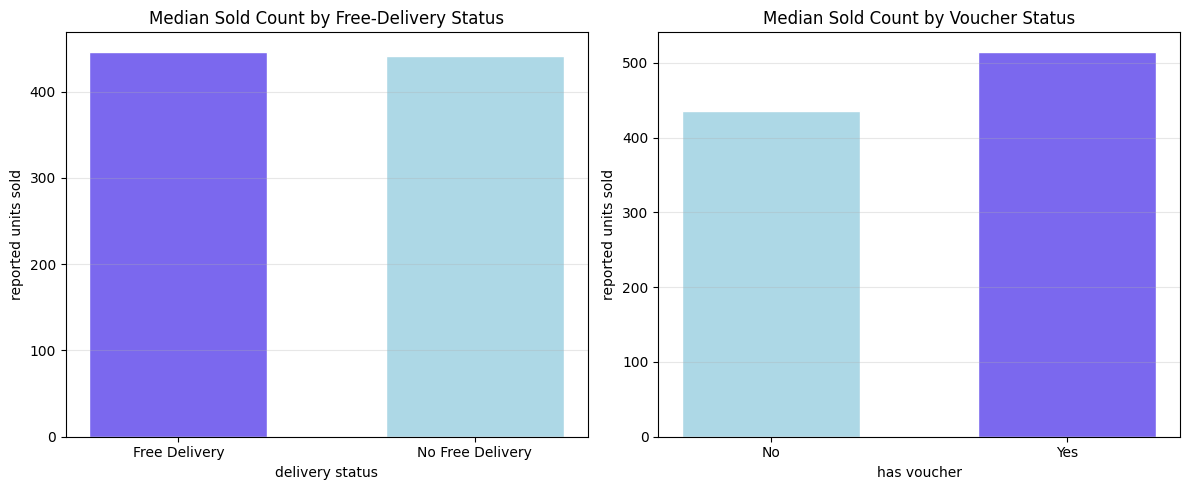

In [11]:
delivery = df.groupby("Delivery")["Sold Count"].median()
voucher = df.groupby("Has Voucher")["Sold Count"].median()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.bar(delivery.index, delivery.values, color=["mediumslateblue", "lightblue"], width=0.6, edgecolor="white")
ax1.set_title("Median Sold Count by Free-Delivery Status")
ax1.set_xlabel("delivery status")
ax1.set_ylabel("reported units sold")
ax1.grid(axis="y", alpha=0.3)

ax2.bar(voucher.index, voucher.values, color=["lightblue", "mediumslateblue"], width=0.6, edgecolor="white")
ax2.set_title("Median Sold Count by Voucher Status")
ax2.set_xlabel("has voucher")
ax2.set_ylabel("reported units sold")
ax2.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

At the overall level, the free-delivery comparison is almost flat, while the voucher group has a somewhat higher median sold count. These bars are descriptive only: they do not control for category, product age, promotion placement or other factors. The next comparison checks whether the voucher pattern is consistent across categories.

**11. voucher comparison inside each category**

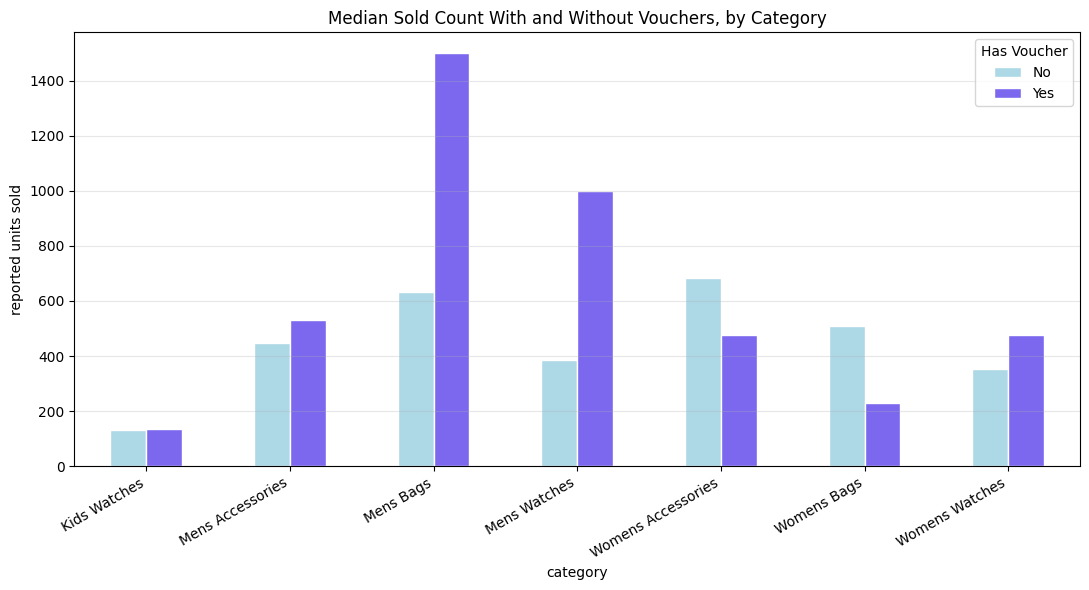

Number of product records in each voucher group:


Has Voucher,No,Yes
Category,,
Kids Watches,125,7
Mens Accessories,147,13
Mens Bags,112,8
Mens Watches,124,36
Womens Accessories,94,26
Womens Bags,182,17
Womens Watches,112,48


In [12]:
voucher_by_category = df.pivot_table(
    index="Category",
    columns="Has Voucher",
    values="Sold Count",
    aggfunc="median"
)

voucher_counts = df.pivot_table(
    index="Category",
    columns="Has Voucher",
    values="Title",
    aggfunc="count",
    fill_value=0
)

voucher_by_category.plot(kind="bar", figsize=(11, 6),
                         color=["lightblue", "mediumslateblue"],
                         edgecolor="white")
plt.title("Median Sold Count With and Without Vouchers, by Category")
plt.xlabel("category")
plt.ylabel("reported units sold")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Has Voucher")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("Number of product records in each voucher group:")
voucher_counts

The category-level chart shows why the overall voucher result must be treated carefully. Voucher listings have higher median sold counts in some categories, but lower medians in others. The voucher groups are also much smaller in several categories. Therefore the correct conclusion is **not** “vouchers increase sales”; it is that voucher status is associated with different sales patterns depending on category, and this dataset alone cannot establish a causal effect.